/usr/local/lib/python3.11/dist-packages/pydantic/_internal/_generate_schema.py:2225: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/pydantic/_internal/_generate_schema.py:2225: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` 

model.safetensors:   0%|          | 0.00/22.9M [00:00<?, ?B/s]

/tmp/ipykernel_19/2405611243.py:132: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
Epoch 1/10:   0%|          | 0/421 [00:00<?, ?it/s]/tmp/ipykernel_19/2405611243.py:150: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Epoch [1/10] | Train Acc: 0.7608 | Val Acc: 0.8740


Epoch [2/10] | Train Acc: 0.9371 | Val Acc: 0.9545


Epoch [3/10] | Train Acc: 0.9694 | Val Acc: 0.9431


... (3 outputs left out)

Epoch [7/10] | Train Acc: 0.9996 | Val Acc: 0.9813


Epoch [8/10] | Train Acc: 1.0000 | Val Acc: 0.9823


Epoch [9/10] | Train Acc: 1.0000 | Val Acc: 0.9826


Epoch [10/10] | Train Acc: 1.0000 | Val Acc: 0.9830

Model: ViT_Tiny_16
Test Accuracy: 0.9802
Precision: 0.9803, Recall: 0.9802, F1: 0.9802


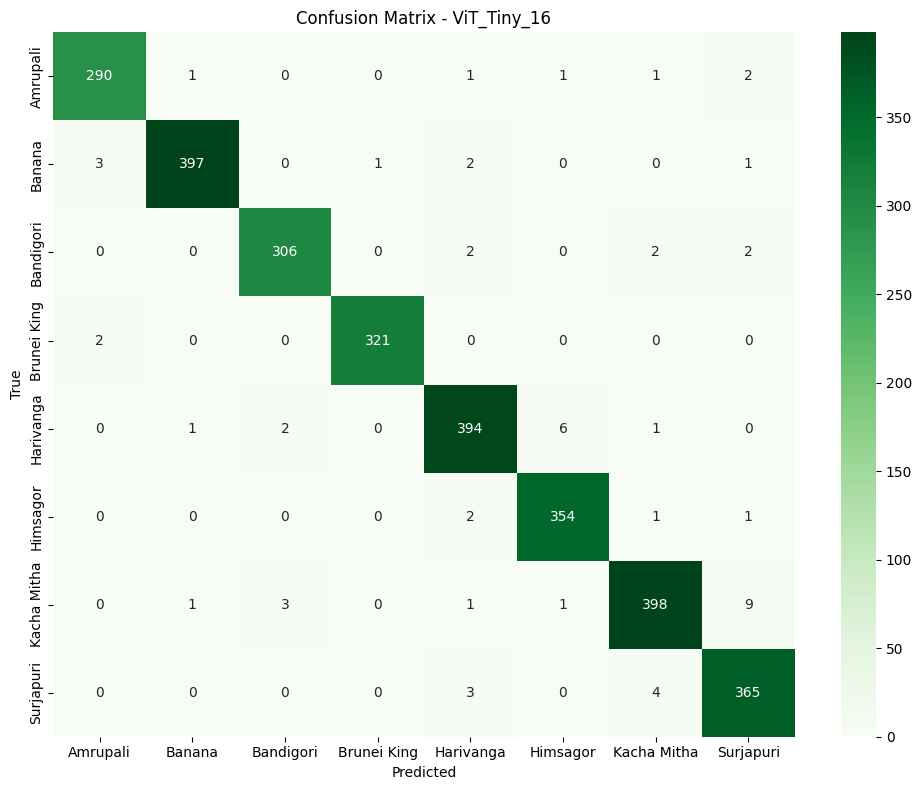

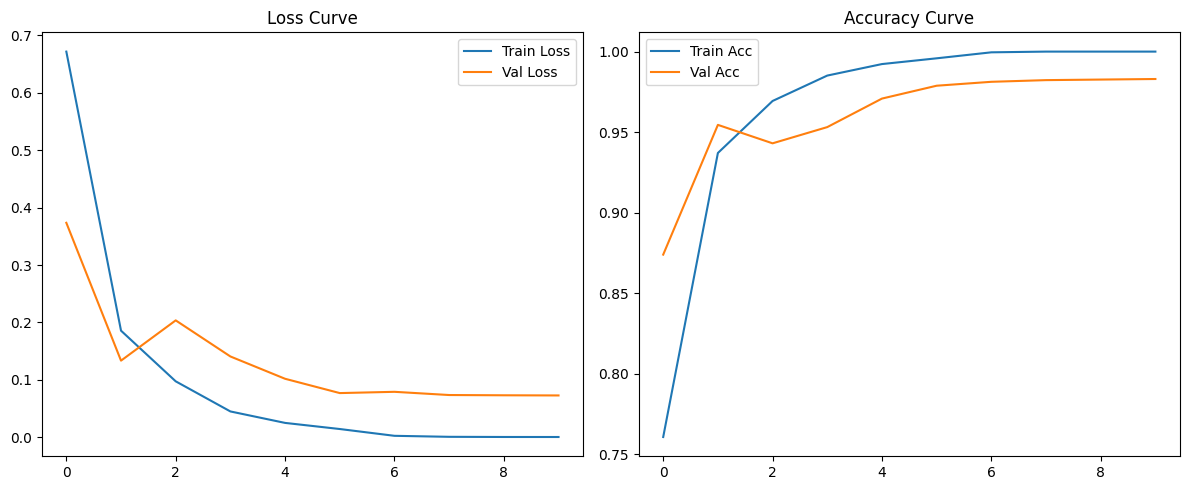

In [1]:
# Install timm if not installed
# !pip install timm

import os
import random
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from tqdm import tqdm
import timm
from torch.cuda.amp import autocast, GradScaler

# ==============================
# Config
# ==============================
dataset_path = "/kaggle/input/mengo-leaf-augmented-dataset/Augmented Images"
device = "cuda" if torch.cuda.is_available() else "cpu"
batch_size = 32
num_epochs = 10
lr = 1e-4
early_stop_patience = 5
num_workers = 2
img_size = 224
model_name = "ViT_Tiny_16"

torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

# ==============================
# Custom Dataset
# ==============================
class MangoDataset(Dataset):
    def __init__(self, img_paths, labels, transform=None):
        self.img_paths = img_paths
        self.labels = labels
        self.transform = transform
        
    def __len__(self):
        return len(self.img_paths)
    
    def __getitem__(self, idx):
        img = Image.open(self.img_paths[idx]).convert("RGB")
        if self.transform:
            img = self.transform(img)
        label = self.labels[idx]
        return img, label

# ==============================
# Load data
# ==============================
classes = sorted(os.listdir(dataset_path))
all_images, all_labels = [], []

for i, cls in enumerate(classes):
    cls_path = os.path.join(dataset_path, cls)
    images = [os.path.join(cls_path, x) for x in os.listdir(cls_path) if x.lower().endswith(('.jpg', '.png'))]
    all_images.extend(images)
    all_labels.extend([i]*len(images))

combined = list(zip(all_images, all_labels))
random.shuffle(combined)
all_images, all_labels = zip(*combined)

total = len(all_images)
train_end = int(0.7 * total)
val_end = int(0.85 * total)

train_paths, val_paths, test_paths = all_images[:train_end], all_images[train_end:val_end], all_images[val_end:]
train_labels, val_labels, test_labels = all_labels[:train_end], all_labels[train_end:val_end], all_labels[val_end:]

# ==============================
# Transforms (dataset already 224x224)
# ==============================
train_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

train_dataset = MangoDataset(train_paths, train_labels, transform=train_transform)
val_dataset = MangoDataset(val_paths, val_labels, transform=val_test_transform)
test_dataset = MangoDataset(test_paths, test_labels, transform=val_test_transform)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=num_workers)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers)

# ==============================
# Model: ViT-Tiny/16 (all layers trainable)
# ==============================
model = timm.create_model('vit_tiny_patch16_224', pretrained=True)

# Get classifier input features
in_features = model.head.in_features if hasattr(model.head, 'in_features') else 192

# Replace classifier head
model.head = nn.Sequential(
    nn.Linear(in_features, 512),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(512, len(classes))
)

# Make all layers trainable
for p in model.parameters():
    p.requires_grad = True

model = model.to(device)

# ==============================
# Loss, optimizer, scheduler
# ==============================
class_counts = np.bincount(train_labels)
class_weights = 1. / class_counts
class_weights = torch.tensor(class_weights, dtype=torch.float).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)
scaler = GradScaler()

# ==============================
# Training Loop
# ==============================
best_val_loss = float('inf')
patience_counter = 0
train_losses, val_losses = [], []
train_accs, val_accs = [], []

for epoch in range(num_epochs):
    model.train()
    running_loss, correct, total = 0, 0, 0

    for imgs, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs}", leave=False):
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()

        with autocast():
            outputs = model(imgs)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()
        _, preds = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (preds == labels).sum().item()

    avg_train_loss = running_loss / len(train_loader)
    train_acc = correct / total
    train_losses.append(avg_train_loss)
    train_accs.append(train_acc)

    model.eval()
    val_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            val_loss += loss.item()
            _, preds = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (preds == labels).sum().item()

    avg_val_loss = val_loss / len(val_loader)
    val_acc = correct / total
    val_losses.append(avg_val_loss)
    val_accs.append(val_acc)
    scheduler.step()

    print(f"Epoch [{epoch+1}/{num_epochs}] | Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f}")

    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        patience_counter = 0
        torch.save(model.state_dict(), f"{model_name}_best.pth")
    else:
        patience_counter += 1
        if patience_counter >= early_stop_patience:
            print("Early stopping triggered.")
            break

# ==============================
# Load Best Model
# ==============================
model.load_state_dict(torch.load(f"{model_name}_best.pth"))

# ==============================
# Test Evaluation
# ==============================
model.eval()
all_preds, all_true = [], []
with torch.no_grad():
    for imgs, labels in test_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        outputs = model(imgs)
        preds = torch.argmax(outputs, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_true.extend(labels.cpu().numpy())

accuracy = accuracy_score(all_true, all_preds)
precision, recall, f1, _ = precision_recall_fscore_support(all_true, all_preds, average='weighted')
cm = confusion_matrix(all_true, all_preds)

print(f"\nModel: {model_name}")
print(f"Test Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}, Recall: {recall:.4f}, F1: {f1:.4f}")

# ==============================
# Confusion Matrix
# ==============================
plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=classes, yticklabels=classes, cmap="Greens")
plt.title(f"Confusion Matrix - {model_name}")
plt.ylabel("True")
plt.xlabel("Predicted")
plt.tight_layout()
plt.savefig("confusion_matrix_vit_tiny.png", dpi=300)
plt.show()

# ==============================
# Training Curves
# ==============================
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.title("Loss Curve")
plt.legend()

plt.subplot(1,2,2)
plt.plot(train_accs, label='Train Acc')
plt.plot(val_accs, label='Val Acc')
plt.title("Accuracy Curve")
plt.legend()

plt.tight_layout()
plt.savefig("training_curves_vit_tiny.png", dpi=300)
plt.show()
